# El EDA de mi proyecto

Es el mismo EDA que el del Titanic, con tus datos: las 9 preguntas, una detrás de otra. Al final se guardan los datos limpios en un CSV, que es el que lee la app.

Debajo de cada bloque hay una celda de texto para escribir lo que has visto y lo que has decidido, en una frase. Si no te acuerdas de cómo se hacía algo, mira titanic.ipynb, eda.ipynb o teoria_eda.ipynb.

## Mis datos

`https://huggingface.co/datasets/AhanaBiswas/WorldHappinessDataset2015-2023/resolve/main/World%20Happiness%20Dataset%202015-2023.csv`
Cada fila es un país con su puntuación y demás factores en determinados años.
¿Qué tienen los países más felices? ¿Cómo ha cambiado España?


## 0. Comprobación

In [105]:
import pandas as pd
import matplotlib
import numpy as np

print("Todo listo")

Todo listo


## 1. ¿Qué tengo?

Empieza por ver qué hay en la tabla.

**1.1** Carga tu CSV de la carpeta datos en una tabla con un nombre que diga qué es (como pisos o titanic) y enseña las primeras filas.

In [106]:
felicidad = pd.read_csv("felicidad.csv")
felicidad.head()


,country,region,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,year
0,Switzerland,Western Europe,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,2015
1,Iceland,Western Europe,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,2015
2,Denmark,Western Europe,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,2015
3,Norway,Western Europe,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503,2015
4,Canada,North America and ANZ,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,2015


**1.2** ¿Cuántas filas y columnas tiene?

In [107]:
print(felicidad.shape) #mostrar filas y columnas


(1367, 10)


**1.3** Mira el info(). ¿De qué tipo es cada columna? ¿Cuáles tienen huecos?

In [108]:
felicidad.info() #información de las columnas y tipos de datos

<class 'pandas.DataFrame'>
RangeIndex: 1367 entries, 0 to 1366
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   country                       1367 non-null   str    
 1   region                        1367 non-null   str    
 2   happiness_score               1367 non-null   float64
 3   gdp_per_capita                1367 non-null   float64
 4   social_support                1367 non-null   float64
 5   healthy_life_expectancy       1366 non-null   float64
 6   freedom_to_make_life_choices  1367 non-null   float64
 7   generosity                    1367 non-null   float64
 8   perceptions_of_corruption     1366 non-null   float64
 9   year                          1367 non-null   int64  
dtypes: float64(7), int64(1), str(2)
memory usage: 145.8 KB


**1.4** Quédate con las columnas que te sirven para tu pregunta, o quita las que sobran.

**1.5** Si los nombres de las columnas están en inglés o son raros, ponles nombres en español.

In [109]:
felicidad.columns= ["pais","region","puntuacion_felicidad","pib_per_capita", "apoyo_social", "esperanza_vida", "libertad", "generosidad", "corrupcion", "año" ]
felicidad.head()


,pais,region,puntuacion_felicidad,pib_per_capita,apoyo_social,esperanza_vida,libertad,generosidad,corrupcion,año
0,Switzerland,Western Europe,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,2015
1,Iceland,Western Europe,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,2015
2,Denmark,Western Europe,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,2015
3,Norway,Western Europe,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503,2015
4,Canada,North America and ANZ,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,2015


Lo que he visto y lo que he decidido: Considero importantes todas las columnas por lo que no eliminaré ninguna. Solamente en corrupción falta un dato que lo rellenaré. Iba a eliminar las regiones pero creo que puede ser interesante utilizarla para obtener distintas estadísticas y gráficos.

## 2. ¿Qué me falta?

Cuenta lo que falta y decide qué haces con cada columna.

**2.1** Cuenta los huecos de cada columna.

In [110]:
felicidad.isna().sum()


pais                    0
region                  0
puntuacion_felicidad    0
pib_per_capita          0
apoyo_social            0
esperanza_vida          1
libertad                0
generosidad             0
corrupcion              1
año                     0
dtype: int64

**2.2** Calcula el porcentaje de huecos de cada columna.

In [111]:
porcentaje = felicidad.isna().sum() / len(felicidad) * 100
porcentaje.round(1)


pais                    0.0
region                  0.0
puntuacion_felicidad    0.0
pib_per_capita          0.0
apoyo_social            0.0
esperanza_vida          0.1
libertad                0.0
generosidad             0.0
corrupcion              0.1
año                     0.0
dtype: float64

**2.3** Decide qué haces con cada columna que tenga huecos: quitar la columna, quitar esas filas o rellenarlos. Hazlo.

In [112]:
felicidad["esperanza_vida"]= felicidad["esperanza_vida"].fillna(felicidad["esperanza_vida"].median()) # rellenamos los valores NaN de la columna esperanza_vida con la mediana de la columna esperanza_vida    
felicidad["esperanza_vida"].isna().sum() # comprobamos que ya no hay valores NaN en la columna esperanza_vida

felicidad["corrupcion"]= felicidad["corrupcion"].fillna(felicidad["corrupcion"].median()) # rellenamos los valores NaN de la columna corrupcion con la mediana de la columna corrupcion
felicidad["corrupcion"].isna().sum() # comprobamos que ya no hay valores NaN en la columna corrupcion


np.int64(0)

**2.4** Comprueba que ya no quedan huecos, o que los que quedan los dejas a propósito.

In [113]:
felicidad.isna().sum() # comprobamos que ya no hay valores NaN en ninguna columna

pais                    0
region                  0
puntuacion_felicidad    0
pib_per_capita          0
apoyo_social            0
esperanza_vida          0
libertad                0
generosidad             0
corrupcion              0
año                     0
dtype: int64

**2.5** Mira con value_counts las columnas de texto. ¿Hay algún hueco disfrazado, como "Unknown", "-" o "N/A"?

In [114]:
felicidad.value_counts()

pais              region                        puntuacion_felicidad  pib_per_capita  apoyo_social  esperanza_vida  libertad  generosidad  corrupcion  año 
Switzerland       Western Europe                7.587                 1.39651         1.34951       0.94143         0.66557   0.29678      0.41978     2015    1
Iceland           Western Europe                7.561                 1.30232         1.40223       0.94784         0.62877   0.43630      0.14145     2015    1
Denmark           Western Europe                7.527                 1.32548         1.36058       0.87464         0.64938   0.34139      0.48357     2015    1
Norway            Western Europe                7.522                 1.45900         1.33095       0.88521         0.66973   0.34699      0.36503     2015    1
Canada            North America and ANZ         7.427                 1.32629         1.32261       0.90563         0.63297   0.45811      0.32957     2015    1
                                       

In [115]:


# 1. Primero convertimos los 0.0 sospechosos en NaN (valores nulos reales)
felicidad["apoyo_social"] = felicidad["apoyo_social"].replace(0.0, np.nan)
felicidad["libertad"] = felicidad["libertad"].replace(0.0, np.nan)

# 2. Rellenamos cada NaN con la mediana específica de su propia región geográfica
felicidad["apoyo_social"] = felicidad["apoyo_social"].fillna(
    felicidad.groupby("region")["apoyo_social"].transform("median")
)

felicidad["libertad"] = felicidad["libertad"].fillna(
    felicidad.groupby("region")["libertad"].transform("median")
)

felicidad.value_counts()

pais              region                        puntuacion_felicidad  pib_per_capita  apoyo_social  esperanza_vida  libertad  generosidad  corrupcion  año 
Switzerland       Western Europe                7.587                 1.39651         1.34951       0.94143         0.665570  0.29678      0.41978     2015    1
Iceland           Western Europe                7.561                 1.30232         1.40223       0.94784         0.628770  0.43630      0.14145     2015    1
Denmark           Western Europe                7.527                 1.32548         1.36058       0.87464         0.649380  0.34139      0.48357     2015    1
Norway            Western Europe                7.522                 1.45900         1.33095       0.88521         0.669730  0.34699      0.36503     2015    1
Canada            North America and ANZ         7.427                 1.32629         1.32261       0.90563         0.632970  0.45811      0.32957     2015    1
                                       

Lo que he visto y lo que he decidido: En este caso al ver que Afghanistan tenía 0.0000 en apoyo social y libertad, puede haber varias filas con 0.0000. He decidido convertir los 0.000 en valores nulos NaN y después rellenar cada NaN con la mediana específica de su propia región geográfica.

## 3. ¿Hay filas repetidas?

Comprueba si hay algo contado dos veces.

**3.1** ¿Cuántas filas repetidas hay?

In [116]:
print("Filas repetidas", felicidad.duplicated().sum(), "en felicidad") # contamos las filas duplicadas en felicidad



Filas repetidas 0 en felicidad


**3.2** Si tienes una columna que identifica cada fila (un id, un nombre), ¿hay algún valor repetido?

In [117]:
print("Paises repetidos", felicidad["pais"].duplicated().sum(), "en felicidad") # contamos los paises duplicados en felicidad



Paises repetidos 1196 en felicidad


**3.3** Decide si las quitas, y hazlo. Si no son la misma fila, no se quitan.

In [118]:
#Decido no quitar o eliminar porque en este caso aunque se repitan los paises, cada vez es un año diferente, por lo que no es un error, es información diferente.


Lo que he visto y lo que he decidido: Cuento las filas duplicadas de paises y ya de antemano sabía que se repetirían muchas filas pero al ser del año 2015 al 2023 cada vez que se repite el nombre del país es por tener distinta información sobre la felicidad en esos años, por lo tanto decido mantener todo lo que tenía hasta ahora.

## 4. ¿Cómo son los números?

Mira los números con el describe, la media, la mediana y un histograma.

**4.1** Haz el describe. ¿Qué te llama la atención?

In [119]:
felicidad.describe() #estadísticas de las columnas numéricas

,puntuacion_felicidad,pib_per_capita,apoyo_social,esperanza_vida,libertad,generosidad,corrupcion,año
count,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000
mean,5.441086,1.019422,1.050593,0.584064,0.453732,0.196260,0.132249,2018.903438
std,1.117909,0.453703,0.320693,0.245029,0.152444,0.113301,0.112518,2.561006
min,1.859000,0.000000,0.058000,0.000000,0.005890,0.000000,0.000000,2015.000000
25%,4.599500,0.696326,0.832022,0.402554,0.359975,0.115000,0.056884,2017.000000
50%,5.440000,1.043000,1.083000,0.612830,0.468660,0.182700,0.097000,2019.000000
75%,6.256300,1.338473,1.299985,0.777602,0.568685,0.252858,0.165890,2021.000000
max,7.842000,2.209000,1.644000,1.141000,0.772000,0.838075,0.587000,2023.000000


In [120]:
#Me llama la atención posibles datos nulos que no se han detectado, por lo que voy a comprobar si hay valores 0.0 en las columnas numéricas, ya que podrían ser datos nulos que no se han detectado.
# Cuenta cuántas veces aparece exactamente el valor 0.0 en cada columna numérica
(felicidad == 0.0).sum() #quiero saber si hay valores 0.0 en las columnas numéricas, ya que podrían ser datos nulos que no se han detectado.

pais                     0
region                   0
puntuacion_felicidad     0
pib_per_capita           9
apoyo_social             0
esperanza_vida           9
libertad                 0
generosidad              9
corrupcion              10
año                      0
dtype: int64

In [122]:
# 1. Volvemos a convertir los 0.0 sospechosos en NaN (valores nulos reales)

felicidad["pib_per_capita"] = felicidad["pib_per_capita"].replace(0.0, np.nan)
felicidad["esperanza_vida"] = felicidad["esperanza_vida"].replace(0.0, np.nan)
felicidad["generosidad"] = felicidad["generosidad"].replace(0.0, np.nan)
felicidad["corrupcion"] = felicidad["corrupcion"].replace(0.0, np.nan)

# 2. Rellenamos cada NaN con la mediana específica de su propia región geográfica
felicidad["pib_per_capita"] = felicidad["pib_per_capita"].fillna(
    felicidad.groupby("region")["pib_per_capita"].transform("median")
)

felicidad["esperanza_vida"] = felicidad["esperanza_vida"].fillna(
    felicidad.groupby("region")["esperanza_vida"].transform("median")
)
felicidad["generosidad"] = felicidad["generosidad"].fillna(
    felicidad.groupby("region")["generosidad"].transform("median")
)
felicidad["corrupcion"] = felicidad["corrupcion"].fillna(
    felicidad.groupby("region")["corrupcion"].transform("median")   
)

felicidad.describe() #estadísticas de las columnas numéricas

,puntuacion_felicidad,pib_per_capita,apoyo_social,esperanza_vida,libertad,generosidad,corrupcion,año
count,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000
mean,5.441086,1.023525,1.050593,0.585963,0.453732,0.197654,0.132609,2018.903438
std,1.117909,0.447568,0.320693,0.241585,0.152444,0.112245,0.112183,2.561006
min,1.859000,0.015300,0.058000,0.005565,0.005890,0.001990,0.000830,2015.000000
25%,4.599500,0.704160,0.832022,0.402554,0.359975,0.116955,0.057000,2017.000000
50%,5.440000,1.043000,1.083000,0.612830,0.468660,0.183860,0.097000,2019.000000
75%,6.256300,1.338473,1.299985,0.777602,0.568685,0.252858,0.165890,2021.000000
max,7.842000,2.209000,1.644000,1.141000,0.772000,0.838075,0.587000,2023.000000


**4.2** Saca la media y la mediana de la columna de números más importante para tu pregunta. ¿Se parecen?

In [128]:
print("Puntuación media de la felicidad:", round(felicidad["puntuacion_felicidad"].mean(), 1)) # puntuación media de la felicidad
print("Puntuación mediana de la felicidad:", round(felicidad["puntuacion_felicidad"].median(), 1)) # puntuación mediana de la felicidad

print(felicidad[felicidad["pais"] == "Spain"]) # mostramos los datos de España

Puntuación media de la felicidad: 5.4
Puntuación mediana de la felicidad: 5.4
       pais          region  puntuacion_felicidad  pib_per_capita  \
35    Spain  Western Europe                6.3290        1.230110   
194   Spain  Western Europe                6.3610        1.342530   
348   Spain  Western Europe                6.4030        1.384398   
505   Spain  Western Europe                6.3100        1.251000   
655   Spain  Western Europe                6.3540        1.286000   
809   Spain  Western Europe                6.4009        1.230535   
961   Spain  Western Europe                6.4910        1.375000   
1112  Spain  Western Europe                6.4760        1.808000   
1261  Spain  Western Europe                6.4360        1.798000   

      apoyo_social  esperanza_vida  libertad  generosidad  corrupcion   año  
35        1.313790        0.955620  0.459510     0.182270    0.063980  2015  
194       1.129450        0.878960  0.375450     0.176650    0.061370  2016

**4.3** Dibuja su histograma.

<Axes: title={'center': 'Distribución de la puntuación de felicidad'}, ylabel='Frequency'>

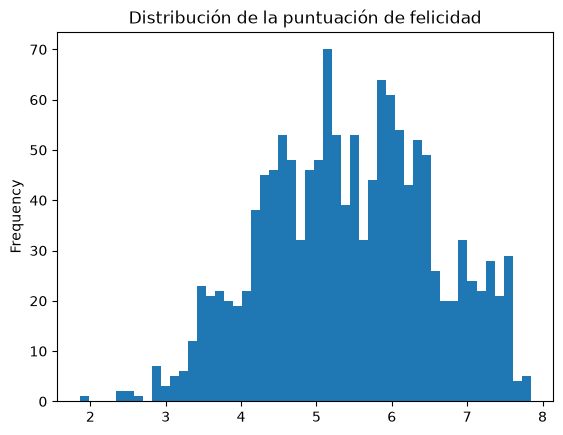

In [132]:
felicidad["puntuacion_felicidad"].plot(kind="hist", bins=50, title="Distribución de la puntuación de felicidad") # histograma de la puntuación de felicidad



**4.4** Haz lo mismo con otra columna de números.

<Axes: title={'center': 'Distribución del PIB per cápita'}, ylabel='Frequency'>

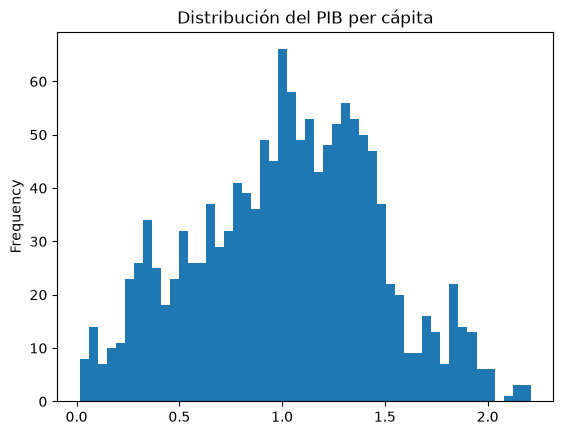

In [133]:
felicidad["pib_per_capita"].plot(kind="hist", bins=50, title="Distribución del PIB per cápita") # histograma del PIB per cápita



Lo que he visto y lo que he decidido:
Al dar la media y mediana de la puntuación de la felicidad 5.4 se ve que no hay ni por arriba ni por debajo valores extremos y son datos bastante equilibrados.

Tener el PIB del pais alto en el caso de España ayuda para tener más felicidad pero se ve que la corrución hace que baje o equilibre bastante la puntuación. Por lo que teniendo algo menos de Pib pero no teniendo tanta corrupción sube o nivela bastante la felicidad. En los demás valores aunque sean distintos en los años no aprecio que se note tanto en la puntuación final, esas 2 características son las que veo que mas influyen.

## 5. ¿Hay algo raro?

Busca los valores extremos y decide si son errores o casos reales.

**5.1** Enseña las 5 filas con el valor más alto de tu columna principal.

In [138]:
felicidad.sort_values("puntuacion_felicidad", ascending=False).head(5) # mostramos los 5 países con mayor puntuación de felicidad]






,pais,region,puntuacion_felicidad,pib_per_capita,apoyo_social,esperanza_vida,libertad,generosidad,corrupcion,año
935,Finland,Western Europe,7.8420,1.44600,1.106000,0.741000,0.691000,0.12400,0.481000,2021
1084,Finland,Western Europe,7.8210,1.89200,1.258000,0.775000,0.736000,0.10900,0.534000,2022
782,Finland,Western Europe,7.8087,1.28519,1.499526,0.961271,0.662317,0.15967,0.477857,2020
1230,Finland,Western Europe,7.8040,1.88800,1.585000,0.535000,0.772000,0.12600,0.535000,2023
626,Finland,Western Europe,7.7690,1.34000,1.587000,0.986000,0.596000,0.15300,0.393000,2019


**5.2** Y las 5 con el más bajo. ¿Hay ceros o valores imposibles?

In [ ]:
felicidad.sort_values("puntuacion_felicidad", ascending=True).head(5) # mostramos los 5 países con menor puntuación de felicidad


,pais,region,puntuacion_felicidad,pib_per_capita,apoyo_social,esperanza_vida,libertad,generosidad,corrupcion,año
1366,Afghanistan,South Asia,1.8590,0.645000,0.774500,0.087000,0.499769,0.093000,0.059000,2023
1365,Lebanon,Middle East and North Africa,2.3920,1.417000,0.476000,0.398000,0.123000,0.061000,0.027000,2023
1229,Afghanistan,South Asia,2.4040,0.758000,0.774500,0.289000,0.499769,0.089000,0.005000,2022
1083,Afghanistan,South Asia,2.5230,0.370000,0.774500,0.126000,0.499769,0.122000,0.010000,2021
934,Afghanistan,South Asia,2.5669,0.300706,0.356434,0.266052,0.499769,0.135235,0.001226,2020


**5.3** Haz el diagrama de caja de esa columna.

<Axes: title={'center': 'Distribución de la puntuación de felicidad'}>

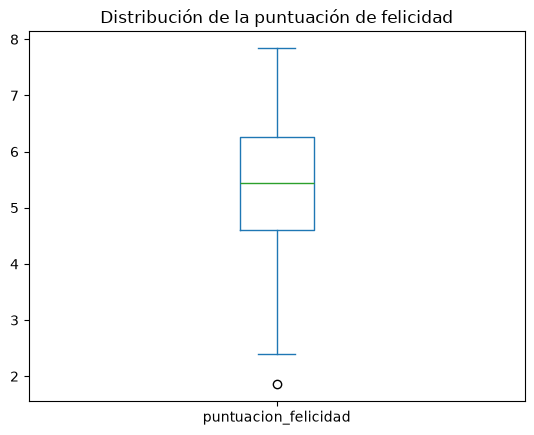

In [ ]:
felicidad["puntuacion_felicidad"].plot(kind="box", title="Distribución de la puntuación de felicidad") # histograma de la puntuación de felicidad



**5.4** Decide qué haces con cada valor raro: si es un error, corrígelo o quítalo; si es real, se queda.

Lo que he visto y lo que he decidido:

En el paso 4 he actuado al ver que seguía habiendo datos extraños con muchos 0.00000 en varias columnas y ahí he decidido actuar y limpiar esos datos convirtiendo primero los 0.0000 en NaN Y después a esos NaN replazandolos por la mediana según la región en la que estuvieran.

## 6. ¿Qué hay más?

Cuántas filas hay de cada tipo.

**6.1** Haz el value_counts de la columna de texto más importante, en número y en porcentaje.

**6.2** Dibújalo en barras.

Lo que he visto y lo que he decidido:

## 7. ¿Cambia algo de un grupo a otro?

Aquí es donde suelen salir los hallazgos.

**7.1** Con groupby, calcula la media o la mediana de tu columna principal en cada grupo.

**7.2** Haz otra comparación con otra columna de grupos.

**7.3** Antes de sacar conclusiones, mira cuántas filas tiene cada grupo. ¿Hay alguno con muy pocas?

Lo que he visto y lo que he decidido:

## 8. ¿Van juntas dos columnas?

Comprueba si dos columnas de números tienen relación.

**8.1** Calcula la correlación entre dos columnas de números.

**8.2** Haz el gráfico de puntos de esas dos columnas.

Lo que he visto y lo que he decidido:

## 9. ¿Qué he aprendido?

**9.1** Haz doble clic en la celda de abajo y escribe tus tres hallazgos, cada uno en una frase con un número. Añade otra con lo que has quitado o cambiado en los datos. Esto es lo que irá en el README y en la presentación.

Escribe aquí tus hallazgos.

## 10. Guardar los datos limpios

**10.1** Guarda la tabla limpia en datos/datos_limpios.csv con to_csv y index=False. Es el archivo que lee la app.

Resultado esperado: un archivo nuevo, datos_limpios.csv, en la carpeta datos.